# Solutions to the exercises of Chapter 12

Sample solutions for [Chapter 12, Black bodies and real surfaces](../../notebooks/part3_radiation/12_radiation_surfaces.ipynb).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import quad
from scipy.optimize import minimize_scalar

try:
    from engtransport import radiation
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    from engtransport import radiation
from engtransport.plotting import use_style

use_style()

## Exercise 1. The incandescent lamp

In [2]:
visible = lambda T: radiation.band_fraction(0.38, 0.78, T)
print(f"tungsten at 2800 K: {100 * visible(2800.0):.1f} % visible")
best = minimize_scalar(lambda T: -visible(T), bounds=(2000.0, 20000.0), method="bounded")
print(f"the visible fraction is largest, {100 * visible(best.x):.1f} %, at {best.x:.0f} K")
print(f"at 3400 K, close to the melting point of tungsten (about 3700 K): {100 * visible(3400.0):.1f} %")

tungsten at 2800 K: 9.7 % visible
the visible fraction is largest, 49.0 %, at 6913 K
at 3400 K, close to the melting point of tungsten (about 3700 K): 19.1 %


At 2800 K a tenth of the emission is visible; the rest heats the room. The visible fraction
would be largest, about 49 %, near 6900 K, a little hotter than the sun's surface, which is
why our eyes are tuned to sunlight. Tungsten melts at about 3700 K, and long before that it
evaporates quickly and blackens the bulb: lamps run near 2800–3000 K and can never be
efficient light sources. LEDs emit only in the visible band and do not have this limit.

## Exercise 2. Why a car warms in the sun

In [3]:
glass_sun = radiation.band_fraction(0.3, 2.7, radiation.T_SUN)
glass_car = radiation.band_fraction(0.3, 2.7, 273.15 + 60.0)
print(f"sunlight passing the glass: {100 * glass_sun:.1f} %; emission of a 60 C interior that could escape: {100 * glass_car:.1e} %")

sunlight passing the glass: 94.0 %; emission of a 60 C interior that could escape: 8.6e-03 %


Glass passes the 94 % of the sunlight that lies in its band (less a few per cent reflected
at its surfaces), but only $9 \times 10^{-5}$ of the infrared emitted by an interior at 60 °C. The interior can
lose heat only by conduction and convection through the glass and body, so it heats until
those losses balance the sunlight that enters. Greenhouses work partly in this way, though
their main effect is to stop the warm air from being carried away.

## Exercise 3. A thermal camera

In [4]:
band = lambda T: radiation.band_fraction(8.0, 14.0, T)
for T_C in (0.0, 20.0):
    T = 273.15 + T_C
    print(f"wall at {T_C:4.1f} C: {100 * band(T):.1f} % of the emission in 8-14 um, {band(T) * radiation.SIGMA_SB * T**4:.1f} W/m2")
T0 = 273.15
dT = 0.01
signal = lambda T: band(T) * radiation.SIGMA_SB * T**4
rel = (signal(T0 + dT) - signal(T0 - dT)) / (2 * dT) / signal(T0)
print(f"in-band signal changes by {100 * rel:.2f} % per kelvin near 0 C (total emission: {100 * 4 / T0:.2f} % per kelvin)")
print(f"at 1300 K only {100 * band(1300.0):.1f} % of the emission is in the band")

wall at  0.0 C: 35.0 % of the emission in 8-14 um, 110.4 W/m2
wall at 20.0 C: 37.0 % of the emission in 8-14 um, 155.1 W/m2
in-band signal changes by 1.81 % per kelvin near 0 C (total emission: 1.46 % per kelvin)
at 1300 K only 5.9 % of the emission is in the band


A third of the emission of a wall at 0–20 °C falls in the 8–14 μm band, the most a band of
this width can hold near room temperature, since the peak lies near 10 μm. The in-band
signal changes by 1.8 % per kelvin, more than the 1.5 % of the total emission, because the
band lies on the short-wavelength side of the peak, where Planck's law rises steeply with
temperature. The band is also a window of the atmosphere. At 1300 K only 6 % of the
emission falls in it, and furnace pyrometers use shorter wavelengths, near 1 μm, where the
signal is strong and changes even faster with temperature.

## Exercise 4. A real coating

graded coating: solar absorptance 0.9090, emissivity at 100 C 0.0514
step at 2.5 um: solar absorptance 0.9191, emissivity at 100 C 0.0501


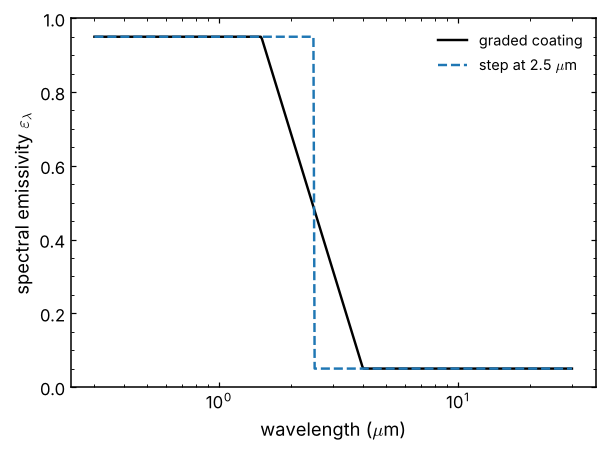

In [5]:
def eps_lambda(lam):
    t = np.clip((np.log(lam) - np.log(1.5)) / (np.log(4.0) - np.log(1.5)), 0.0, 1.0)
    return 0.95 + (0.05 - 0.95) * t


def weighted(T, lam_lo=0.05, lam_hi=1000.0):
    E = lambda lam: radiation.planck_spectral_emissive_power(lam, T)
    pts = [1.5, 4.0]
    num = quad(lambda l: eps_lambda(l) * E(l), lam_lo, lam_hi, points=pts, limit=400)[0]
    den = quad(E, lam_lo, lam_hi, points=pts, limit=400)[0]
    return num / den


step = radiation.step_surface(2.5, 0.95, 0.05)
alpha_real, eps_real = weighted(radiation.T_SUN), weighted(373.15)
print(f"graded coating: solar absorptance {alpha_real:.4f}, emissivity at 100 C {eps_real:.4f}")
print(f"step at 2.5 um: solar absorptance {step['absorptance']():.4f}, emissivity at 100 C {step['emissivity'](373.15):.4f}")
lam = np.geomspace(0.3, 30.0, 400)
fig, ax = plt.subplots(figsize=(5.4, 4.0))
ax.semilogx(lam, eps_lambda(lam), "k-", label="graded coating")
ax.semilogx(lam, np.where(lam < 2.5, 0.95, 0.05), "C0--", label=r"step at 2.5 $\mu$m")
ax.set_xlabel(r"wavelength ($\mu$m)")
ax.set_ylabel(r"spectral emissivity $\varepsilon_\lambda$")
ax.set_ylim(0, 1)
ax.legend(loc="upper right")
plt.show()

**Figure S12.1.** The graded coating of Exercise 4 and the step model with the same mean
cutoff.

The graded coating absorbs 1 % less sunlight than the step model (0.909 against 0.919),
because it already reflects part of the near infrared between 1.5 and 2.5 μm, and emits 3 %
more at 100 °C (0.051 against 0.050), because its absorption reaches into the
short-wavelength tail of the plate's own emission. Both differences are small here,
because the transition lies in the gap between the two spectra (Fig. 12.2a); for a hotter
absorber, whose emission moves towards shorter wavelengths, a gradual transition costs
more, which is why coatings for concentrating collectors need a steep one.